# SANATAN: Root-Parity Gated Angular Attention - Interactive Demo

**Bhargav Patel** · Independent Researcher · [Paper (preprint)](paper/sanatan_v2.pdf) · MIT License

SANATAN is a linear attention mechanism built on **root-parity gating**: over $2\times2$ real
matrices, $i^2=-1$ has two canonical orthogonal solutions, and each feature dimension of a token
softly selects one of them. The resulting $d$-bit binary label gates per-dimension interaction
between queries and keys inside an angular kernel. In the linear ($p{=}1$) case the mechanism
admits an **exact constant-size recurrent state**, so decoding needs no KV cache.

This notebook demonstrates, end to end on a small model you can train in minutes on CPU:

1. the algebra ($i_+$, $i_-$, and the orientation marker $S(\theta)$),
2. the exact factorization identity $\Phi(q)^\top\Phi(k) = (1+r_qr_k)(1+\cos\Delta\theta)$,
3. training a small character-level SANATAN language model ($p{=}1$),
4. **verifying the exact recurrence**: parallel and recurrent computation agree to float32 precision,
5. streaming text generation from the constant state (no KV cache),
6. measured gate statistics (how binary the learned roots are, and how much closed gates leak),
7. the memory/latency breakeven versus softmax KV-cache decoding.

**Honest scope** (matching the paper's corrected claims): the gating is *per-dimension* - the
$2^d$ count is a label space, not isolated memory sectors; the constant-state property holds only
for $p{=}1$-trained models (the paper measures a $\approx{+}5$ nat penalty for deploying $p{>}1$
models through the recurrence); and at 184M scale SANATAN outperforms the evaluated pre-2022
constant-memory baselines under a shared recipe while remaining behind matched-recipe Gated
Linear Attention - closing that gap, or transferring root-parity gating into such architectures,
is open research.

In [1]:
import math, time, urllib.request
import numpy as np
import jax, jax.numpy as jnp
import flax.linen as nn
import optax
import matplotlib.pyplot as plt

jax.config.update('jax_default_matmul_precision', 'highest')  # phases need full f32
print('JAX', jax.__version__, '| devices:', jax.devices())

JAX 0.11.2 | devices: [CpuDevice(id=0)]


## 1. The algebra: two matrix roots of $-1$

In the complex numbers, $x^2=-1$ has two solutions, $\pm i$. Their real-matrix representations
are the two oriented rotations of the plane by $\pi/2$ - the only *orthogonal* real $2\times2$
solutions of $X^2=-I$:

In [2]:
i_plus  = np.array([[0., -1.], [1.,  0.]])
i_minus = np.array([[0.,  1.], [-1., 0.]])
print('i_plus^2  =\n', i_plus @ i_plus)
print('i_minus^2 =\n', i_minus @ i_minus)

# The combination S(theta) = cos(t) i_+ + sin(t) i_- is NOT generally a root:
# S(theta)^2 = -(cos t - sin t)^2 I. It is an ORIENTATION MARKER: the sign of
# beta(t) = cos t - sin t flips at t = pi/4 and tells which root dominates.
for t in [0.0, np.pi/8, np.pi/4, np.pi/2]:
    S = np.cos(t) * i_plus + np.sin(t) * i_minus
    beta = np.cos(t) - np.sin(t)
    print(f'theta={t:5.3f}  S^2 = {(S@S)[0,0]:+.3f} I  (= -(cos-sin)^2 = {-beta**2:+.3f})  sign(beta)={np.sign(beta):+.0f}')

i_plus^2  =
 [[-1.  0.]
 [ 0. -1.]]
i_minus^2 =
 [[-1.  0.]
 [ 0. -1.]]
theta=0.000  S^2 = -1.000 I  (= -(cos-sin)^2 = -1.000)  sign(beta)=+1
theta=0.393  S^2 = -0.293 I  (= -(cos-sin)^2 = -0.293)  sign(beta)=+1
theta=0.785  S^2 = -0.000 I  (= -(cos-sin)^2 = -0.000)  sign(beta)=+1
theta=1.571  S^2 = -1.000 I  (= -(cos-sin)^2 = -1.000)  sign(beta)=-1


The sign of $\beta(\theta)$ is the binary **root label**. Across $d$ feature
dimensions this gives each token a $d$-bit label; the feature map below turns label agreement
into a per-dimension gate on the attention score.

## 2. The SANATAN attention module

Six channels per dimension: $\Phi(x) = [\,1,\ \cos\theta,\ \sin\theta,\ r,\ r\cos\theta,\ r\sin\theta\,]$,
with $\theta = \varphi(\text{activation}) + t\lambda$ (bounded learned rotation) and
$r = \tanh(\gamma(\cos(\theta+\omega)-\sin(\theta+\omega)))$ the soft root ($\gamma=10$, as in the
paper; the follow-up architecture makes it learnable). Scores are normalized and raised to a
power $p$; **only $p{=}1$ admits the exact recurrence**. As in the paper's evaluated models, the
LM below also uses a learned absolute positional embedding (disclosed in the paper; it caps the
trained context).

In [3]:
GAMMA = 10.0

class RMSNorm(nn.Module):
    d: int
    @nn.compact
    def __call__(self, x):
        w = self.param('w', nn.initializers.ones, (self.d,))
        var = jnp.mean(x.astype(jnp.float32) ** 2, axis=-1, keepdims=True)
        return x * jax.lax.rsqrt(var + 1e-6) * w

class SanatanAttn(nn.Module):
    d: int
    nh: int
    power: float = 1.0
    @nn.compact
    def __call__(self, x):
        B, S, D = x.shape
        hd = D // self.nh
        scale = 1.0 / math.sqrt(hd)
        HP = jax.lax.Precision.HIGHEST
        W_q = self.param('W_q', nn.initializers.normal(0.02), (D, D))
        W_k = self.param('W_k', nn.initializers.normal(0.02), (D, D))
        W_v = self.param('W_v', nn.initializers.normal(0.02), (D, D))
        W_o = self.param('W_out', nn.initializers.normal(0.02), (D, D))
        omega = self.param('omega', nn.initializers.constant(math.pi / 4), (self.nh, hd))
        lambda_raw = self.param('lambda_raw', nn.initializers.zeros, (self.nh, hd))
        lam = jnp.tanh(lambda_raw.astype(jnp.float32)) * 0.01

        q = (x @ W_q).astype(jnp.float32).reshape(B, S, self.nh, hd) * scale
        k = (x @ W_k).astype(jnp.float32).reshape(B, S, self.nh, hd) * scale
        v = (x @ W_v).astype(jnp.float32).reshape(B, S, self.nh, hd)

        tq = jnp.pi * (q / (1 + jnp.abs(q)))          # phase map (C^1)
        tk = jnp.pi * (k / (1 + jnp.abs(k)))
        rq = jnp.tanh(GAMMA * (jnp.cos(tq + omega) - jnp.sin(tq + omega)))   # soft root
        rk = jnp.tanh(GAMMA * (jnp.cos(tk + omega) - jnp.sin(tk + omega)))
        pos = jnp.arange(S)[None, :, None, None].astype(jnp.float32)
        tq, tk = tq + pos * lam, tk + pos * lam        # bounded temporal rotation

        def phi(t, r):
            return jnp.concatenate([jnp.ones_like(t), jnp.cos(t), jnp.sin(t),
                                    r, r * jnp.cos(t), r * jnp.sin(t)], -1)
        pq = jnp.transpose(phi(tq, rq), (0, 2, 1, 3))  # (B, H, S, 6hd)
        pk = jnp.transpose(phi(tk, rk), (0, 2, 1, 3))
        vt = jnp.transpose(v, (0, 2, 1, 3))

        s = jnp.matmul(pq, jnp.swapaxes(pk, -2, -1), precision=HP) / (4.0 * hd + 1e-6)
        s = jnp.power(jnp.maximum(s, 0.0), self.power)
        s = jnp.where(jnp.tril(jnp.ones((S, S), bool))[None, None], s, 0.0)
        attn = s / (s.sum(-1, keepdims=True) + 1e-6)
        out = jnp.transpose(jnp.matmul(attn, vt, precision=HP), (0, 2, 1, 3)).reshape(B, S, D)
        return (out @ W_o).astype(x.dtype)

class Block(nn.Module):
    d: int; nh: int; ffn: int; power: float
    @nn.compact
    def __call__(self, x):
        x = x + SanatanAttn(self.d, self.nh, self.power)(RMSNorm(self.d)(x))
        h = RMSNorm(self.d)(x)
        g = nn.Dense(self.ffn, use_bias=False)(h)
        u = nn.Dense(self.ffn, use_bias=False)(h)
        return x + nn.Dense(self.d, use_bias=False)(jax.nn.silu(g) * u)

class CausalLM(nn.Module):
    vocab: int; d: int = 128; n_layers: int = 4; nh: int = 4; ffn: int = 256
    max_len: int = 512; power: float = 1.0
    @nn.compact
    def __call__(self, ids):
        tok = self.param('tok_emb', nn.initializers.normal(0.02), (self.vocab, self.d))
        pe  = self.param('pos_emb', nn.initializers.normal(0.02), (self.max_len, self.d))
        x = tok[ids] + pe[jnp.arange(ids.shape[1])]
        for _ in range(self.n_layers):
            x = Block(self.d, self.nh, self.ffn, self.power)(x)
        return RMSNorm(self.d)(x) @ tok.T

print('model code ready')

model code ready


## 3. The factorization identity, verified numerically

$\Phi(q)^\top\Phi(k) = (1 + r_q r_k)(1 + \cos\Delta\theta)$ holds *exactly* for any values of
$r$ (hard or soft) - it is an algebraic identity, and the whole mechanism rests on it. For hard
roots $r\in\{-1,+1\}$ the first factor is the $\{0,2\}$ parity gate.

In [4]:
rng = np.random.default_rng(0)
tq_, tk_ = rng.uniform(-np.pi, np.pi, 10000), rng.uniform(-np.pi, np.pi, 10000)
for name, (a, b) in {
    'hard roots': (rng.choice([-1., 1.], 10000), rng.choice([-1., 1.], 10000)),
    'soft roots': (np.tanh(rng.normal(0, 3, 10000)), np.tanh(rng.normal(0, 3, 10000))),
}.items():
    phi = lambda t, r: np.stack([np.ones_like(t), np.cos(t), np.sin(t), r, r*np.cos(t), r*np.sin(t)], -1)
    lhs = (phi(tq_, a) * phi(tk_, b)).sum(-1)
    rhs = (1 + a * b) * (1 + np.cos(tq_ - tk_))
    print(f'{name}: max |Phi(q).Phi(k) - (1+rq rk)(1+cos dtheta)| = {np.abs(lhs - rhs).max():.2e}')

hard roots: max |Phi(q).Phi(k) - (1+rq rk)(1+cos dtheta)| = 1.33e-15
soft roots: max |Phi(q).Phi(k) - (1+rq rk)(1+cos dtheta)| = 1.33e-15


## 4. Train a small character-level model ($p{=}1$)

A few hundred steps on tiny-Shakespeare - enough to show the mechanism learns and to give the
recurrence and gate statistics something real to measure. (The paper's 184M models were trained
for billions of tokens; at that scale single-stage $p{=}1$ converges slowly and the paper uses a
two-stage recipe - $p{=}2$ pretraining, then brief $p{=}1$ adaptation.)

In [5]:
URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
try:
    text = urllib.request.urlopen(URL, timeout=30).read().decode()
except Exception as e:
    print('download failed, using tiny built-in corpus:', e)
    text = ('to be, or not to be, that is the question: whether tis nobler in the mind '
            'to suffer the slings and arrows of outrageous fortune, or to take arms '
            'against a sea of troubles and by opposing end them. ') * 400
chars = sorted(set(text))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
data = np.array([stoi[c] for c in text], dtype=np.int32)
print(f'{len(text):,} characters, vocab {V}')

SL, BATCH, STEPS, LR = 128, 16, 250, 3e-3
model = CausalLM(vocab=V, power=1.0)
params = model.init(jax.random.PRNGKey(0), jnp.zeros((1, SL), jnp.int32))
n_par = sum(x.size for x in jax.tree.leaves(params))
print(f'{n_par/1e6:.2f}M parameters')

tx = optax.chain(optax.clip_by_global_norm(1.0),
                 optax.adamw(optax.linear_schedule(0, LR, 20), weight_decay=0.1))
opt_state = tx.init(params)

def get_batch(key):
    ix = jax.random.randint(key, (BATCH,), 0, len(data) - SL - 1)
    return jnp.stack([jnp.asarray(data[i:i + SL + 1]) for i in ix])

@jax.jit
def train_step(params, opt_state, batch):
    def loss_fn(p):
        logits = model.apply(p, batch[:, :-1])
        lp = jax.nn.log_softmax(logits.astype(jnp.float32), -1)
        return -jnp.mean(jnp.take_along_axis(lp, batch[:, 1:, None], -1))
    loss, g = jax.value_and_grad(loss_fn)(params)
    upd, opt_state = tx.update(g, opt_state, params)
    return optax.apply_updates(params, upd), opt_state, loss

key = jax.random.PRNGKey(1)
t0 = time.time()
for step in range(1, STEPS + 1):
    key, sub = jax.random.split(key)
    params, opt_state, loss = train_step(params, opt_state, get_batch(sub))
    if step % 50 == 0 or step == 1:
        print(f'step {step:4d}  loss {float(loss):.3f}  ({time.time()-t0:.0f}s)')
print('done')

1,115,394 characters, vocab 65


0.73M parameters


step    1  loss 4.188  (5s)


step   50  loss 2.604  (21s)


step  100  loss 2.557  (37s)


step  150  loss 2.403  (53s)


step  200  loss 2.408  (70s)


step  250  loss 2.370  (87s)
done


## 5. The exact constant-state recurrence, verified

At $p{=}1$ the factorized score lets us swap summation order: instead of attending over all past
tokens, we keep two running sums per head,
$S_t = S_{t-1} + \Phi(k_t)v_t^\top$ and $z_t = z_{t-1} + \Phi(k_t)$, and retrieve with
$\Phi(q_t)^\top S_t / (\Phi(q_t)^\top z_t + \epsilon)$. The state size never grows. Below we run
the **same trained weights** through both paths and compare every logit.

In [6]:
def make_recurrent(params, model):
    cfg = model
    P = params['params']
    D, nh = cfg.d, cfg.nh
    hd = D // nh
    scale, eps = 1.0 / math.sqrt(hd), 4.0 * hd * 1e-6
    tok, pe = P['tok_emb'], P['pos_emb']
    L = []
    for i in range(cfg.n_layers):
        b = P[f'Block_{i}']
        a = b['SanatanAttn_0']
        L.append(dict(n1=b['RMSNorm_0'], n2=b['RMSNorm_1'],
                      Wq=a['W_q'], Wk=a['W_k'], Wv=a['W_v'], Wo=a['W_out'],
                      om=a['omega'], lam=jnp.tanh(a['lambda_raw']) * 0.01,
                      Fg=b['Dense_0']['kernel'], Fu=b['Dense_1']['kernel'], Fd=b['Dense_2']['kernel']))
    nf = P['RMSNorm_0']
    rms = lambda p, x: x * jax.lax.rsqrt(jnp.mean(x**2, -1, keepdims=True) + 1e-6) * p['w']
    phi = lambda t, r: jnp.concatenate([jnp.ones_like(t), jnp.cos(t), jnp.sin(t),
                                        r, r*jnp.cos(t), r*jnp.sin(t)], -1)
    def step(carry, inp):
        St, Zt = carry
        tok_id, t = inp
        x = tok[tok_id] + pe[t]
        nS, nZ = [], []
        for i, Lr in enumerate(L):
            h = rms(Lr['n1'], x)
            q = (h @ Lr['Wq']).reshape(-1, nh, hd) * scale
            k = (h @ Lr['Wk']).reshape(-1, nh, hd) * scale
            v = (h @ Lr['Wv']).reshape(-1, nh, hd)
            tq = jnp.pi * (q / (1 + jnp.abs(q))); tk = jnp.pi * (k / (1 + jnp.abs(k)))
            rq = jnp.tanh(GAMMA * (jnp.cos(tq + Lr['om']) - jnp.sin(tq + Lr['om'])))
            rk = jnp.tanh(GAMMA * (jnp.cos(tk + Lr['om']) - jnp.sin(tk + Lr['om'])))
            pq = phi(tq + t * Lr['lam'], rq); pk = phi(tk + t * Lr['lam'], rk)
            S = St[i] + pk[..., :, None] * v[..., None, :]
            Z = Zt[i] + pk
            num = jnp.einsum('bhf,bhfd->bhd', pq, S)
            den = jnp.einsum('bhf,bhf->bh', pq, Z)[..., None] + eps
            x = x + (num / den).reshape(-1, D) @ Lr['Wo']
            h2 = rms(Lr['n2'], x)
            x = x + (jax.nn.silu(h2 @ Lr['Fg']) * (h2 @ Lr['Fu'])) @ Lr['Fd']
            nS.append(S); nZ.append(Z)
        return (jnp.stack(nS), jnp.stack(nZ)), rms(nf, x) @ tok.T
    def init_state(B):
        return (jnp.zeros((cfg.n_layers, B, nh, 6 * hd, hd), jnp.float32),
                jnp.zeros((cfg.n_layers, B, nh, 6 * hd), jnp.float32))
    @jax.jit
    def forward(ids):
        B, S = ids.shape
        _, logits = jax.lax.scan(step, init_state(B), (ids.T, jnp.arange(S)))
        return jnp.transpose(logits, (1, 0, 2))
    return forward, jax.jit(step), init_state

rec_forward, rec_step, rec_init = make_recurrent(params, model)

val = jnp.stack([jnp.asarray(data[i:i + SL]) for i in range(0, 4 * SL, SL)])  # 4 held-out-ish seqs
lg_par = model.apply(params, val)
lg_rec = rec_forward(val)
ce = lambda lg: float(-jnp.mean(jnp.take_along_axis(
    jax.nn.log_softmax(lg[:, :-1].astype(jnp.float32), -1), val[:, 1:, None], -1)))
print(f'max |parallel - recurrent| over every logit : {float(jnp.max(jnp.abs(lg_par - lg_rec))):.3e}')
print(f'loss, parallel attention                    : {ce(lg_par):.6f}')
print(f'loss, constant-state recurrence             : {ce(lg_rec):.6f}')
hd = model.d // model.nh
state_kb = model.n_layers * model.nh * (6 * hd * hd + 6 * hd) * 4 / 1024
print(f'recurrent state, this model: {state_kb:.0f} KB total — constant for any sequence length')

max |parallel - recurrent| over every logit : 4.292e-06


loss, parallel attention                    : 2.534033
loss, constant-state recurrence             : 2.534033
recurrent state, this model: 396 KB total — constant for any sequence length


The paper verifies the same property at 184M parameters: recurrent and
parallel evaluation agree to within $10^{-4}$ nats, and the two-stage $p{=}1$ model matches its
full parallel parent (held-out loss **3.951 vs 3.966**) while deploying with a fixed **14.4 MB**
state. (Precision matters: under TF32 matrix multiplication the paper measures pointwise logit
deviations growing by an order of magnitude - the phase pipeline wants true float32.)

## 6. Streaming generation - no KV cache

Generation uses only the recurrent step: feed one character, update $(S, z)$, sample, repeat.
Memory is constant no matter how long we generate.

In [7]:
def generate(prompt, n=300, temp=0.8, seed=42):
    carry = rec_init(1)
    ids = [stoi.get(c, 0) for c in prompt]
    t = 0
    logits = None
    for tok_id in ids:
        carry, logits = rec_step(carry, (jnp.array([tok_id]), jnp.array(t)))
        t += 1
    key = jax.random.PRNGKey(seed)
    out = list(prompt)
    for _ in range(n):
        key, sub = jax.random.split(key)
        nxt = int(jax.random.categorical(sub, logits[0] / temp))
        out.append(chars[nxt])
        carry, logits = rec_step(carry, (jnp.array([nxt]), jnp.array(t)))
        t += 1
    return ''.join(out)

print(generate('ROMEO: ', n=300))
print('\n(undertrained demo model — the point is the mechanism: constant memory, token by token)')

ROMEO: heis wowont sing id wis.
LAS:
But lllld ponepee ilin ll hedo!
AUCETI d and thersherevent lin.
ANTINTENTAS:
O:
NENI fily ke
LUS:
Y:
Anin worovem d htit hos ps my
An sthatherre beray qut t worsos lllarederel hindlflllautht but m ave, ridam by, de whoumy,
Whathe, st mimp he snded y!
Ancor her s t rrind

(undertrained demo model — the point is the mechanism: constant memory, token by token)


## 7. Measured gate statistics

How binary are the learned roots, and how much do nominally closed gates leak? (At 184M the
paper measures: $|r|>0.99$ on 87.8% of activations, mean mismatched-dimension gate 0.057 versus
2 when open, and token pairs mismatching on 49.3% of dimensions - per-dimension gating, exactly
as the corrected claim states.)

fraction of activations with |r| > 0.99 : 0.888
mean per-dimension mismatch between pairs: 0.484
mean gate value (1 + rq*rk) on mismatch  : 0.054   (open gate = 2)


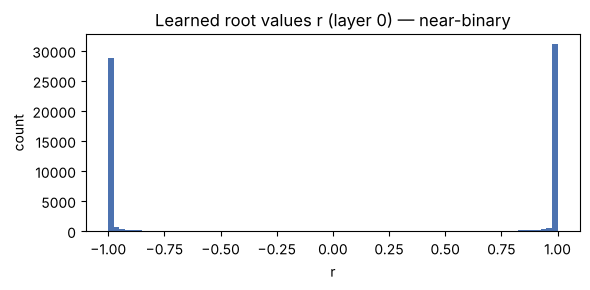

In [8]:
P0 = params['params']['Block_0']['SanatanAttn_0']
D, nh = model.d, model.nh; hd = D // nh
x = params['params']['tok_emb'][val] + params['params']['pos_emb'][jnp.arange(SL)]
h = x * jax.lax.rsqrt(jnp.mean(x**2, -1, keepdims=True) + 1e-6) * params['params']['Block_0']['RMSNorm_0']['w']
q = (h @ P0['W_q']).reshape(-1, nh, hd) / math.sqrt(hd)
t_ = jnp.pi * (q / (1 + jnp.abs(q)))
r = np.asarray(jnp.tanh(GAMMA * (jnp.cos(t_ + P0['omega']) - jnp.sin(t_ + P0['omega'])))).reshape(-1, hd)
prod = r[:400, None, :] * r[None, :400, :]
print(f'fraction of activations with |r| > 0.99 : {(np.abs(r) > 0.99).mean():.3f}')
print(f'mean per-dimension mismatch between pairs: {(prod < 0).mean():.3f}')
print(f'mean gate value (1 + rq*rk) on mismatch  : {(1 + prod)[prod < 0].mean():.3f}   (open gate = 2)')

plt.figure(figsize=(6, 3))
plt.hist(r.ravel(), bins=80, color='#4C72B0')
plt.title('Learned root values r (layer 0) — near-binary')
plt.xlabel('r'); plt.ylabel('count'); plt.tight_layout(); plt.show()

## 8. Memory and latency: constant state vs KV cache

Memory is analytic; latency is a microbenchmark of the attention decode path on *this* machine
(the paper's numbers, on a workstation GPU at 184M config: recurrent step **0.153 ms/token**
constant in $n$, versus softmax KV-cache decode 0.490 ms at 1K up to 7.325 ms at 32K - a
$3.2\times$ to $48\times$ advantage, with memory crossover at $n\approx195$ tokens).

demo model: constant SANATAN state = 0.4 MB (all layers)
  softmax KV cache @ n= 1,024:       4.2 MB   (  10.3x)
  softmax KV cache @ n= 2,048:       8.4 MB   (  20.7x)
  softmax KV cache @ n= 8,192:      33.6 MB   (  82.7x)
  softmax KV cache @ n=32,768:     134.2 MB   ( 331.0x)
  softmax KV cache @ n=131,072:     536.9 MB   (1324.0x)
  memory crossover: n ~ 99 tokens

paper model (184M): constant SANATAN state = 14.4 MB (all layers)
  softmax KV cache @ n= 1,024:      75.5 MB   (   5.3x)
  softmax KV cache @ n= 2,048:     151.0 MB   (  10.5x)
  softmax KV cache @ n= 8,192:     604.0 MB   (  42.0x)
  softmax KV cache @ n=32,768:    2415.9 MB   ( 168.0x)
  softmax KV cache @ n=131,072:    9663.7 MB   ( 672.2x)
  memory crossover: n ~ 195 tokens



latency on this machine (CPU):
  SANATAN recurrent step: 0.094 ms/token (constant in n)


  softmax decode @ n=  512:   0.723 ms/token  ( 7.7x slower)


  softmax decode @ n= 2048:   2.278 ms/token  (24.1x slower)


  softmax decode @ n= 8192:  28.009 ms/token  (296.8x slower)


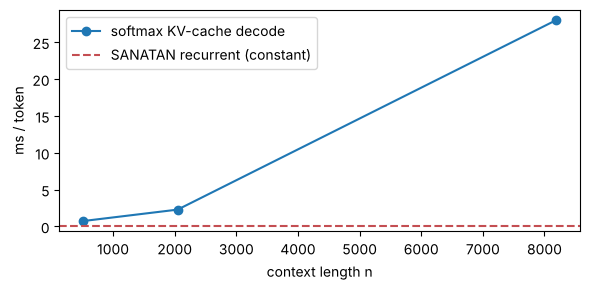

In [9]:
def mem_table(L, H, hd, D, label):
    state = L * H * (6 * hd * hd + 6 * hd) * 4 / 1e6
    print(f'{label}: constant SANATAN state = {state:.1f} MB (all layers)')
    for n in [1024, 2048, 8192, 32768, 131072]:
        kv = 2 * n * D * L * 4 / 1e6
        print(f'  softmax KV cache @ n={n:>6,}: {kv:9.1f} MB   ({kv/state:6.1f}x)')
    print(f'  memory crossover: n ~ {state * 1e6 / (2 * D * L * 4):.0f} tokens')

mem_table(4, 4, 32, 128, 'demo model')
print()
mem_table(12, 12, 64, 768, 'paper model (184M)')

# latency microbenchmark at the demo config, on this machine
Dm, Hm, hdm, Lm = 128, 4, 32, 4
key = jax.random.PRNGKey(0)
Wq = jax.random.normal(key, (Lm, Dm, Dm)) * 0.02; Wo = jax.random.normal(key, (Lm, Dm, Dm)) * 0.02

@jax.jit
def softmax_decode(x, K, Vv):
    for i in range(Lm):
        q = (x @ Wq[i]).reshape(1, Hm, hdm)
        k = K[i].reshape(-1, Hm, hdm); v = Vv[i].reshape(-1, Hm, hdm)
        a = jax.nn.softmax(jnp.einsum('bhd,nhd->bhn', q, k) / math.sqrt(hdm), -1)
        x = x + jnp.einsum('bhn,nhd->bhd', a, v).reshape(1, Dm) @ Wo[i]
    return x

@jax.jit
def sanatan_decode(x, S, Z):
    for i in range(Lm):
        q = (x @ Wq[i]).reshape(1, Hm, hdm)
        t = jnp.pi * (q / (1 + jnp.abs(q)))
        r = jnp.tanh(GAMMA * (jnp.cos(t) - jnp.sin(t)))
        pq = jnp.concatenate([jnp.ones_like(t), jnp.cos(t), jnp.sin(t), r, r*jnp.cos(t), r*jnp.sin(t)], -1)
        num = jnp.einsum('bhf,hfd->bhd', pq, S[i])
        den = jnp.einsum('bhf,hf->bh', pq, Z[i])[..., None] + 1e-4
        x = x + (num / den).reshape(1, Dm) @ Wo[i]
    return x

def bench(fn, *a, reps=20):
    jax.block_until_ready(fn(*a))
    t0 = time.perf_counter()
    for _ in range(reps):
        r = fn(*a)
    jax.block_until_ready(r)
    return (time.perf_counter() - t0) / reps * 1000

x0 = jnp.zeros((1, Dm))
S0 = jnp.zeros((Lm, Hm, 6 * hdm, hdm)); Z0 = jnp.zeros((Lm, Hm, 6 * hdm))
t_rec = bench(sanatan_decode, x0, S0, Z0)
print(f'\nlatency on this machine ({jax.devices()[0].platform.upper()}):')
print(f'  SANATAN recurrent step: {t_rec:.3f} ms/token (constant in n)')
ns, ts = [512, 2048, 8192], []
for n in ns:
    K = jnp.zeros((Lm, n, Dm)); Vv = jnp.zeros((Lm, n, Dm))
    t = bench(softmax_decode, x0, K, Vv)
    ts.append(t)
    print(f'  softmax decode @ n={n:>5}: {t:7.3f} ms/token  ({t/t_rec:4.1f}x slower)')

plt.figure(figsize=(6, 3))
plt.plot(ns, ts, 'o-', label='softmax KV-cache decode')
plt.axhline(t_rec, color='#C44E52', ls='--', label='SANATAN recurrent (constant)')
plt.xlabel('context length n'); plt.ylabel('ms / token'); plt.legend(); plt.tight_layout(); plt.show()

## Citation and status

```bibtex
@article{patel2026sanatan,
  title  = {SANATAN: Root-Parity Gated Angular Attention with an Exact Constant-State Recurrent Form},
  author = {Patel, Bhargav},
  year   = {2026},
  note   = {Preprint}
}
```

Full-scale training code (JAX/TPU, 184M, the matched GLA/RetNet baselines, and the seeded
deep-stream evaluation protocol) accompanies the paper. Questions, critiques, and collaboration
on the open problems - gate-construction ablations, long-context evaluation under the
recurrence, and transferring root-parity gating into gated linear architectures - are welcome.